# 02 — Does faster first response increase conversion?

Statistical inference following the **pre-registered** [analysis plan](../reports/analysis_plan.md) (committed before any of this code existed). Interpretation and recommendation: [analysis report](../reports/analysis_report.md).

Thin notebook: the computations live in `src/lead_funnel/analysis/` (`inference.py`, `regression.py`, `robustness.py`, `report.py`) and are unit-tested; `lead-funnel report` runs exactly the same function.

Runtime ≈ 6 minutes with the defaults (200 bootstrap refits, 20 synthetic datasets). Set `LF_BOOTSTRAP` / `LF_SEEDS` for a quick run.

In [1]:
import json
import os

import pandas as pd
from IPython.display import Image, Markdown, display

from lead_funnel.analysis import eda, inference
from lead_funnel.analysis.report import run_inference
from lead_funnel.config import get_settings
from lead_funnel.ingestion.warehouse import connect

pd.set_option("display.precision", 4)
settings = get_settings()
with connect(settings.db_path, read_only=True) as con:
    leads = eda.load_leads(con)
    calls = inference.load_calls(con)
truth_file = settings.raw_dir / "_ground_truth.json"
truth = json.loads(truth_file.read_text(encoding="utf-8")) if truth_file.exists() else None

results = run_inference(
    leads,
    calls,
    settings.reports_dir / "figures",
    truth=truth,
    bootstrap=int(os.environ.get("LF_BOOTSTRAP", 200)),
    seeds=int(os.environ.get("LF_SEEDS", 20)),
)
print(f"{len(leads):,} leads analysed")

50,000 leads analysed


## H1 — SLA met vs missed: the naïve association

Two-proportion z-test, Newcombe CI for the difference, and effect sizes. With ~50 000 leads the p-value is astronomically small; the **effect size** and the comparison with the +2 pp threshold carry the decision.

In [2]:
results.h1

,comparison,n_met,n_missed,conv_met,conv_missed,diff_pp,diff_ci_pp,z,p_value,relative_risk,odds_ratio,cohens_h,practically_relevant
0,all leads,20736,29025,0.2122,0.1159,9.6291,"[8.96, 10.30]",29.1829,3.1981e-187,1.8308,2.0546,0.2627,True
1,business hours only,20354,18136,0.2130,0.1167,9.6306,"[8.90, 10.36]",25.2506,1.1167e-140,1.8254,2.0488,0.2622,True
2,answered leads only,20736,26912,0.2122,0.1244,8.7786,"[8.10, 9.46]",25.7455,3.6204e-146,1.7056,1.8957,0.2365,True


## Correlations and H2 — ANOVA with assumption checks

Spearman (ranks) captures the score-response relation that Pearson understates on skewed data. H2a should reject (channels really differ in speed); H2b should **not** (call duration does not depend on channel) — a correct null result.

In [3]:
display(results.correlations)
results.anova

,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,lead_score,hours,47648,-0.0406,7.3328e-19,-0.1763,0.0000e+00
1,lead_score,n_touches,47648,0.4187,0.0000e+00,0.4114,0.0000e+00
2,hours,n_touches,47648,-0.0490,1.0680e-26,-0.1129,7.6812e-135


,hypothesis,n,levene_p,min_shapiro_p,anova_F,anova_p,welch_F,welch_p,kruskal_p,eta_sq,omega_sq,test_used,reject_H0
0,H2a log10(response hours) ~ channel,47648,1.1517e-189,2.2163e-15,2458.6239,0.0000,2028.442,0.0000,0.0000,1.3406e-01,1.3400e-01,welch,True
1,H2b call duration ~ channel,49087,3.5278e-01,6.9558e-24,0.9916,0.3955,1.021,0.3821,0.6597,6.0604e-05,-5.1297e-07,classic,False


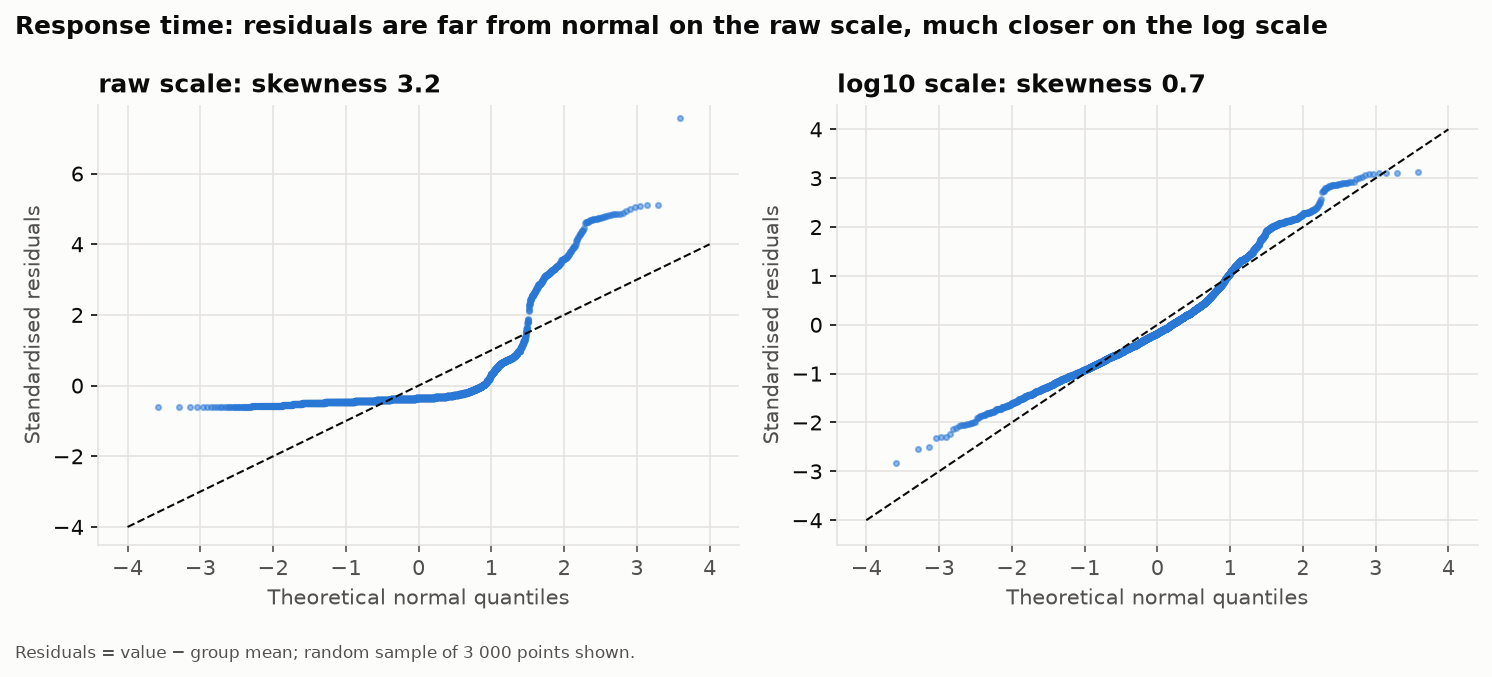

In [4]:
display(Image(results.figures["qq"]))

## H3 — adjusted logistic model

Adjustment set from the causal DAG: lead score, channel, source, company size. Mediators (follow-ups, meetings) are deliberately left out.

In [5]:
display(results.coefficients.drop(columns=["term", "ci"]))
display(results.binned)  # functional-form check
results.calibration

,model,estimate,se,p_value,odds_ratio,ame_pp
0,naïve,-0.2642,0.0101,7.7771e-150,0.7678,NaN
1,adjusted,-0.1814,0.0104,9.9703e-69,0.8341,-1.997


,response_bin,odds_ratio,ci_low,ci_high
0,≤ 1 h,1.0000,NaN,NaN
1,1-4 h,0.8964,0.8399,0.9568
2,4-24 h,0.5879,0.5401,0.6400
3,> 24 h,0.4186,0.3664,0.4782
4,never answered,0.0513,0.0312,0.0843


,n,predicted,observed
decile,,,
0,4977,0.0113,0.0108
1,4976,0.0320,0.0305
2,4976,0.0511,0.0502
3,4976,0.0712,0.0643
4,4976,0.0944,0.1015
5,4976,0.1232,0.1222
6,4976,0.1615,0.1674
7,4976,0.2157,0.2189
8,4976,0.3016,0.2978


Stratifying by lead-score quintile shows the confounding mechanism directly: inside groups of similar quality the SLA gap is much smaller than the crude gap.

In [6]:
s = results.stratified
crude, within = s.attrs["crude_gap_pp"], s.attrs["stratified_gap_pp"]
display(Markdown(f"Crude gap **{crude:.1f} pp** → within score quintiles **{within:.1f} pp**"))
s

Crude gap **9.6 pp** → within score quintiles **5.5 pp**

,score_quintile,n,share_sla_met,conv_met,conv_missed,gap_pp
0,1,10227,0.2803,0.0495,0.0265,2.3035
1,2,9828,0.3710,0.0858,0.0540,3.1820
2,3,10106,0.4169,0.1571,0.1023,5.4808
3,4,10467,0.4770,0.2249,0.1651,5.9771
4,5,9133,0.5493,0.4305,0.3226,10.7893


## Robustness and multiple testing

In [7]:
display(results.sensitivity)
results.segments

,variant,n,naive_gap_pp,odds_ratio,or_ci_low,or_ci_high,effect_on_missed_pp,policy_lift_pp,robust
0,primary (SLA 60 min),49761,9.6291,0.8341,0.8174,0.8512,3.6465,2.4884,True
1,SLA 30 min,49761,9.8993,0.8341,0.8174,0.8512,2.9033,2.4884,True
2,SLA 120 min,49761,10.2394,0.8341,0.8174,0.8512,4.6674,2.4884,True
3,errors included (239 leads),50000,9.5567,0.8442,0.8277,0.8611,3.4457,2.3659,True
4,business hours only,38490,9.6306,0.8453,0.8044,0.8882,1.8916,1.3506,False


,segment,value,n,diff_pp,p_value,p_holm,p_bh,sig_value,sig_holm,sig_bh
0,channel,email,8950,11.2150,1.1588e-38,1.6223e-37,3.6695e-38,True,True,True
1,channel,partner_referral,5358,15.2438,6.0765e-31,5.4689e-30,9.6212e-31,True,True,True
2,channel,phone,10977,8.9708,3.8047e-30,2.6633e-29,5.5607e-30,True,True,True
3,channel,web_form,24476,7.9250,8.4295e-73,1.5173e-71,8.0080e-72,True,True,True
4,lead_source,direct,6018,9.8318,5.6799e-24,2.8400e-23,7.1946e-24,True,True,True
5,lead_source,event,5049,11.2032,5.0544e-22,2.0218e-21,6.0021e-22,True,True,True
6,lead_source,organic_search,14834,8.4987,4.0885e-51,6.1327e-50,1.5536e-50,True,True,True
7,lead_source,paid_search,10878,7.5198,1.3111e-35,1.5733e-34,3.1139e-35,True,True,True
8,lead_source,partner,5973,15.4500,1.6112e-35,1.7723e-34,3.4014e-35,True,True,True
9,lead_source,social,7009,5.8088,1.8556e-20,5.5669e-20,2.0740e-20,True,True,True


## Comparison with the truth

Only possible because the data is synthetic; computed **after** the estimates.

,label,estimate,ci_low,ci_high,truth,unit,truth_in_ci
0,naïve,0.7678,0.7527,0.7832,0.8500,odds ratio,False
1,adjusted,0.8341,0.8174,0.8512,0.8500,odds ratio,True
2,missed SLA: naïve gap,9.6291,8.9634,10.2981,3.2474,pp,False
3,missed SLA: adjusted,3.6465,3.2526,4.0596,3.2474,pp,False
4,all within 30 min: adjusted,2.4884,2.2645,2.7134,2.2281,pp,False


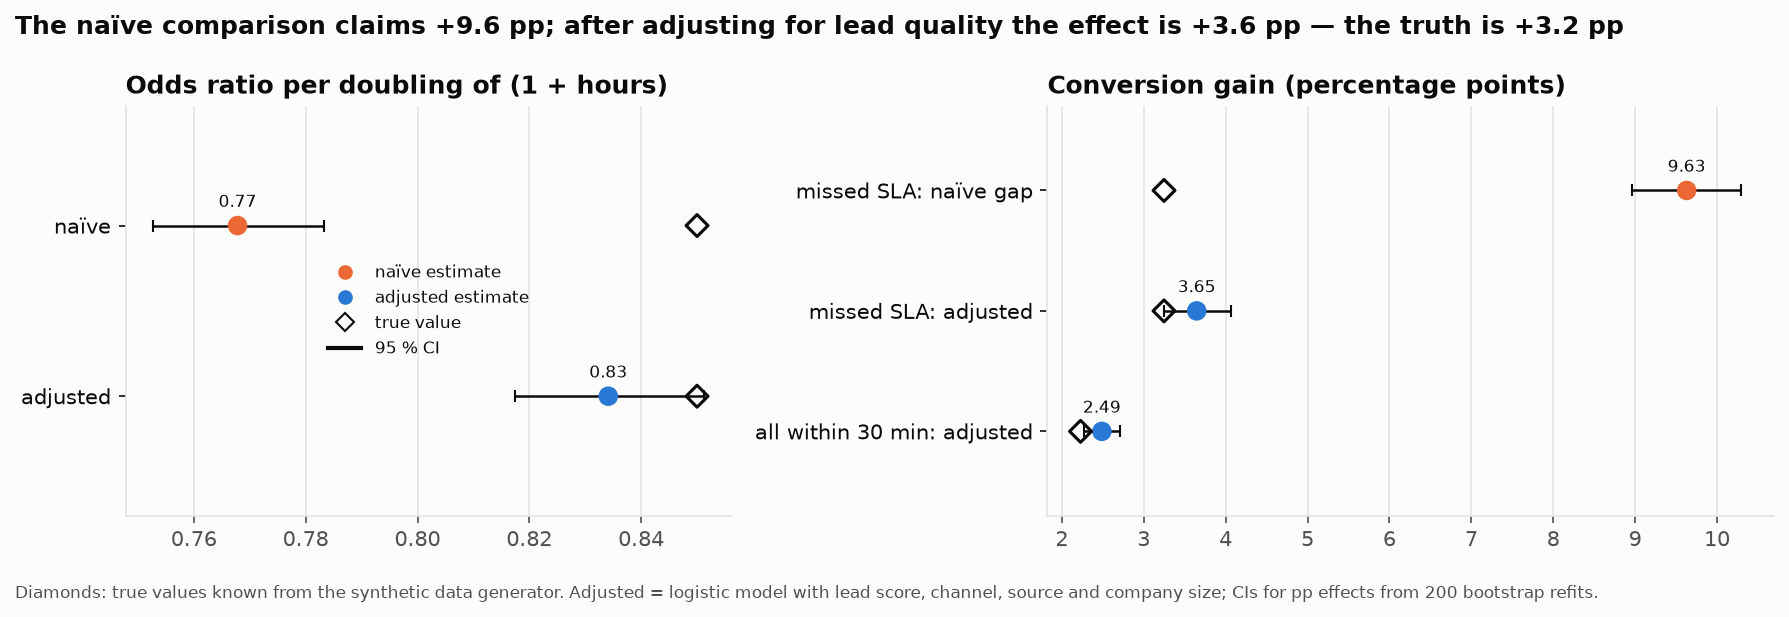

In [8]:
if results.comparison is not None:
    display(results.comparison.drop(columns=["quantity"]))
    display(Image(results.figures["effect_comparison"]))

,quantity,mean_estimate,mean_truth,mean_error,se_of_mean_error,sd_across_seeds
0,beta,-0.1618,-0.1625,0.0007,0.0023,0.0101
1,effect_on_missed_pp,3.2536,3.2689,-0.0153,0.0396,0.1900
2,policy_lift_pp,2.2049,2.2148,-0.0100,0.0220,0.1024


95 % CI for β covers the truth in **90%** of 20 datasets

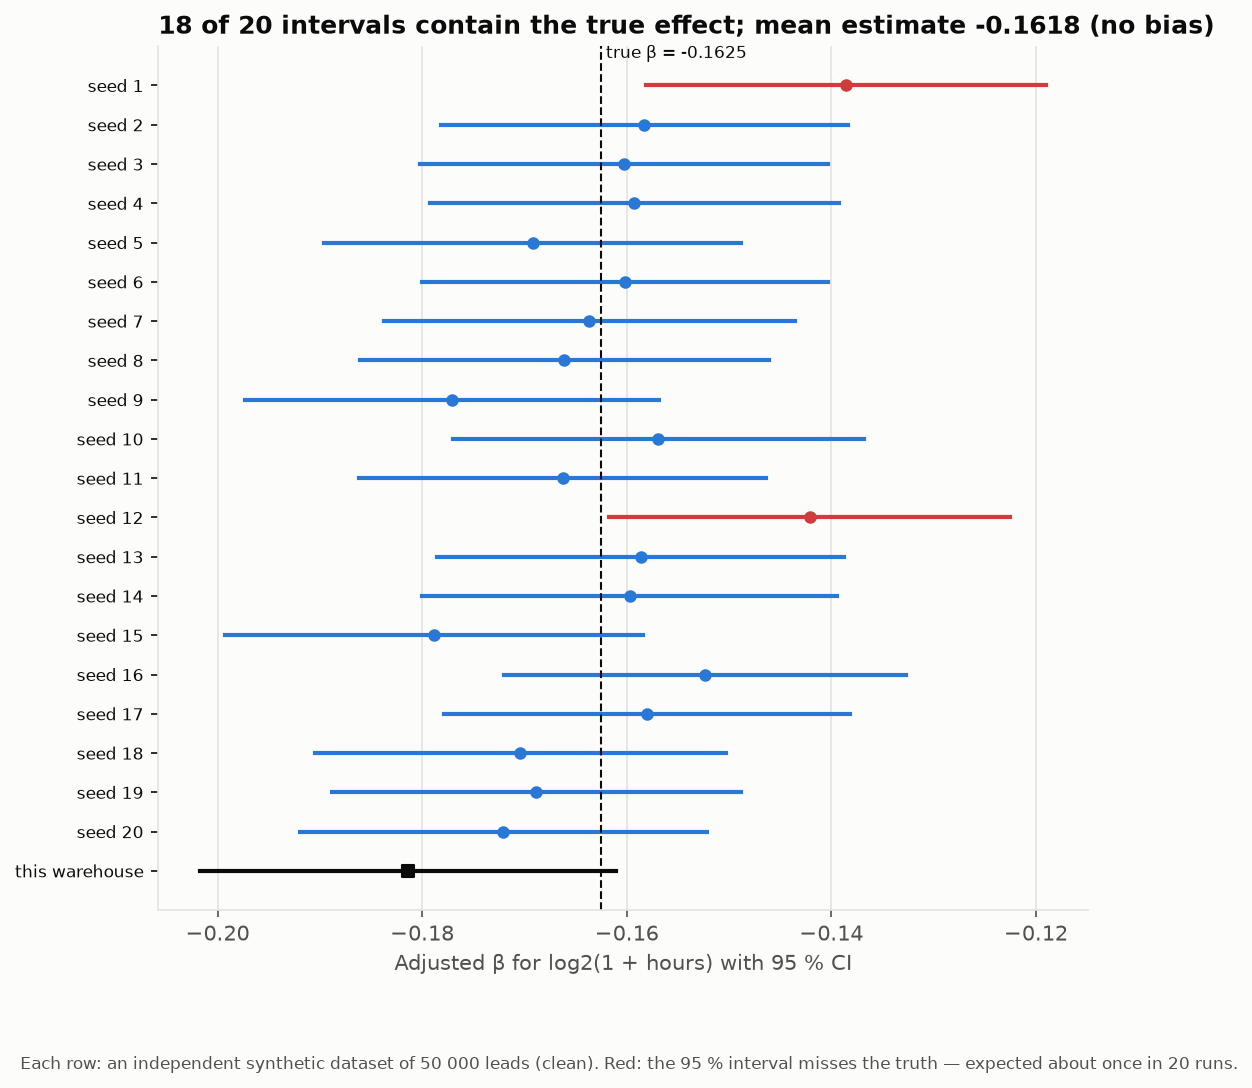

In [9]:
if results.seed_summary is not None:
    display(results.seed_summary)
    attrs = results.seed_summary.attrs
    coverage = f"{attrs['beta_coverage']:.0%}"
    seeds = attrs["seeds"]
    display(Markdown(f"95 % CI for β covers the truth in **{coverage}** of {seeds} datasets"))
    display(Image(results.figures["seed_study"]))

## Conclusion

- The raw SLA gap (≈ +9.6 pp) is about **two-thirds confounding** by lead quality.
- After adjustment the effect is real and practically relevant: leads that missed the SLA would convert ≈ **3-4 pp** more if answered within 30 minutes.
- The estimator is **unbiased** across independent datasets; a single dataset's 95 % interval can miss the truth, as it should about once in twenty.
- The gain is concentrated in leads waiting overnight or at weekends (business-hours effect below the +2 pp threshold) → test **out-of-hours coverage** with an experiment ([report §6](../reports/analysis_report.md#6-recommendation-confirm-with-an-experiment)).